# **Лабораторная работа 1. Работа с графами.**

**Предварительная подготовка.**

**СКОПИРУЙТЕ ФАЙЛ**

ОБЯЗАТЕЛЬНО ЗДЕСЬ НАПИШИТЕ ФАМИЛИЮ.

Сдаете в LMS вы ipynb версию скачанную (не colab). При необходимости, вы можете сдать дополнительно файл (офомленный в любом читаемом виде).

Пожалуйста, не надо использовать ИИ для ответов на вопросы и написания кода. Отвечать на вопросы лучше прям здесь, под заданиями, где были написаны вопросыю

**Цель:** изучить алгоритмы поиска в глубину (DFS) и в ширину (BFS), реализовать их для разных представлений графа, проанализировать сложность и сравнить производительность экспериментально.

# 1. Изучите ```perf_counter()``` и ```perf_counter_ns()```.

`perf_counter()` и `perf_counter_ns()` — это функции из модуля `time`, предоставляющие **доступ к высокоточным таймерам**.

Посмотрите на пример измерения времени работы какого-то фрагмента кода.

In [ ]:
import time

# perf_counter() — возвращает время в СЕКУНДАХ (float)
start = time.perf_counter()
s = sum(range(100000))  # некоторый измеряемый фрагмент кода
end = time.perf_counter()
print(end - start)

# perf_counter_ns() — возвращает время в НАНОСЕКУНДАХ (int)
start_ns = time.perf_counter_ns()
s = sum(range(100000)) # некоторый измеряемый фрагмент кода
end_ns = time.perf_counter_ns()
print(end_ns - start_ns)

0.006781225999986873
6241258


# 2. Как проводить измерение времени работы алгоритма и глубины рекурсии (для рекурсивных алгоритмов)

Напишем простую рекурсивную функцию для подсчета факториала числа. И на её примере посмотрим как измерять время работы алгоритма, а также глубину рекурсии.

In [ ]:
import sys
sys.setrecursionlimit(10000)
def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n-1)

Проведем анализ сложности этой функции.

Для нее верно следующее рекуррентное соотношение
```
T(n) = T(n-1) + O(1)
T(1) = O(1)
```

Выполним процесс развертывания рекурсивной функции.

```
T(n) = T(n-1) + 1
T(n) = [T(n-2) + 1] + 1 = T(n-2) + 2
T(n) = [T(n-3) + 1] + 2 = T(n-3) + 3
```

**на шаге k получим**
```
T(n) = T(n-k) + k
```
При k = n-1 достигнем базового случая (доходим до T(1)):

```
T(n) = T(1) + (n-1)
T(n) = 1 + (n-1)
T(n) = n
```

**Временная сложность:** **O(n)** — линейная

## Анализ времени (через функцию измерения времени)

Напишем функцию, которая измеряет время работы этой функции на разных размерах входных данных, чтобы на реальных замерах убедиться, что время работы функции линейное.

In [ ]:
def measure_factorial_time(n, repeats=10): # repeats число повторов для одной сессии измерений
    times = []

    for _ in range(repeats):
        start = time.perf_counter_ns()
        result = factorial(n)
        end = time.perf_counter_ns()
        times.append(end - start)

    # убираем выбросы (минимальное и максимальное время) и усредняем
    if repeats > 2:
        times.sort()
        times = times[1:-1]

    avg_time = sum(times) / len(times)
    return avg_time, result

times_ns = [] # тут будет время работы
init_n = list(range(100, 1001, 50)) # тут будут исходные размеры входных данных

for n in init_n:
    time_ns, _ = measure_factorial_time(n, repeats=10)
    times_ns.append(time_ns)

Теперь визуализируем результаты, чтобы на графике убедиться в корректности наших выводов о времени работы функции.

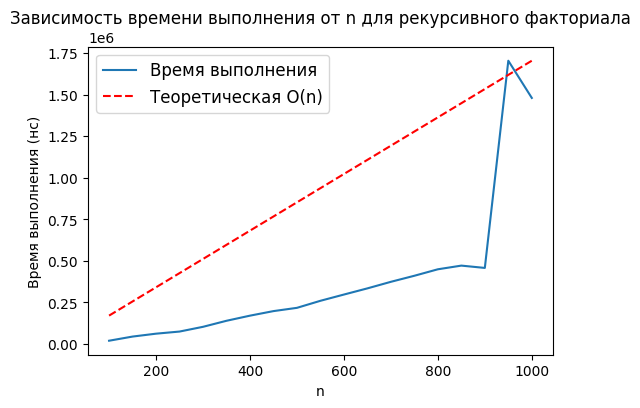

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(init_n, times_ns, label='Время выполнения')


import numpy as np
theoretical_log = [n for n in init_n]
scale_factor = max(times_ns) / max(theoretical_log)
theoretical_time = [t * scale_factor for t in theoretical_log]
plt.plot(init_n, theoretical_time, 'r--', label='Теоретическая O(n)')


plt.xlabel('n')
plt.ylabel('Время выполнения (нс)')
plt.title('Зависимость времени выполнения от n для рекурсивного факториала')
plt.legend(fontsize=12, loc='upper left')

Измерение времени зависит от множества факторов: загрузки процессора, фоновых процессов, и даже (внезапно!) температуры CPU и т.д. Сегодня алгоритм выполняется 1.2 мс, завтра -- 1.5 мс, и непонятно, что изменилось. Поэтому используют еще один подход -- измеряют количество операций. Ведь количество операций -- детерминировано: для факториала 5 всегда будет 5 умножений.

## Анализ времени (через измерение числа операций)

Перепишем функцию факториала, чтобы можно было измерить число операций. К сожалению, придется немного испортить нашу функцию.

In [ ]:
def factorial(n):
    def _fact(n):
        nonlocal operations
        operations += 1  # каждая проверка условия - операция
        if n <= 1:
            return 1
        operations += 3
        # умножение, вычитание и вызов функции это еще три операции
        return n * _fact(n-1)

    operations = 0
    result = _fact(n)
    return result, operations

In [ ]:
def count_factorial_operations(n, repeats=10):
    times = []
    result = None

    for _ in range(repeats):
        result, ops = factorial(n)

    return result, ops

init_n = list(range(100, 1001, 50))
times_ns = []
operations_list = []

for n in init_n:
    _, ops = count_factorial_operations(n, repeats=10)
    operations_list.append(ops)

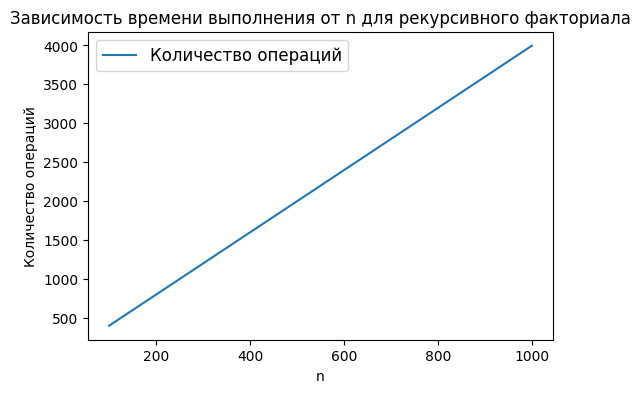

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(init_n, operations_list, label='Количество операций')

plt.xlabel('n')
plt.ylabel('Количество операций')
plt.title('Зависимость времени выполнения от n для рекурсивного факториала')
plt.legend(fontsize=12, loc='upper left')

Обратите внимание, на графике нет выбросов и зависимость более четкая. Также не нужно выполнять несколько повторов.

## Анализ глубины рекурсии

Перепишем функцию, чтобы можно было измерить максимальную глубину рекурсии

In [ ]:
def factorial(n):
    def _fact(n, depth):
        nonlocal max_depth
        max_depth = max(max_depth, depth)

        if n <= 1:
            return 1

        return n * _fact(n-1, depth + 1)

    max_depth = 0
    result = _fact(n, 1)  # начинаем с глубины 1
    return result, max_depth

init_n = list(range(100, 1001, 50))
depth_list = []

for n in init_n:
    _, depth = factorial(n)
    depth_list.append(depth)

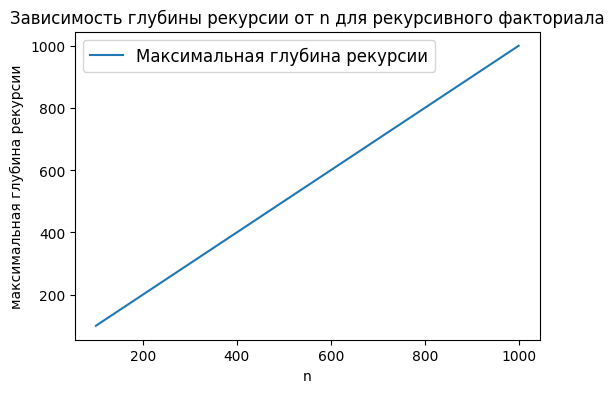

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(init_n, depth_list, label='Максимальная глубина рекурсии')

plt.xlabel('n')
plt.ylabel('максимальная глубина рекурсии')
plt.title('Зависимость глубины рекурсии от n для рекурсивного факториала')
plt.legend(fontsize=12, loc='upper left')

Фактически, в данном примере, для нас глубина рекурсии показывает количество используемой памяти. Видим, что максимальная глубина рекурсии линейно зависит от размера входных данных. Учитывая, что на каждом вызове у нас создается/копируется константное количество переменных -- память используемая (то есть пространтсвенная сложность) **O(N)**

 # Предварительная подготовка, работа с библиотекой `NetworkX`

В этом задании будет выполнена предварительная подготовка, которая вам пригодится для выполнения заданий. Будем говорить о генерации графов разной плотности.

**Плотность графа** определяется как отношение количества рёбер к максимально возможному:
- Для **неориентированного графа** без петель: максимум рёбер = n·(n-1)/2
- Для **ориентированного графа** без петель: максимум рёбер = n·(n-1)

**Классификация:**
- **Разреженный (sparse):** E ≈ O(V)
- **Средней плотности:** E ≈ O(V·log V)
- **Плотный (dense):** E ≈ O(V²)


Мы будем для генерации использовать библиотеку `NetworkX`

Сначала её нужно установить.

In [ ]:
!pip install networkx matplotlib

Ниже посмотрим основные возможности библиотеки.

**Ориентированный и неориентированный граф (создание)**


In [ ]:
import networkx as nx

G = nx.Graph() # Неориентированный граф
DG = nx.DiGraph() # Ориентированный граф


G.add_node(1) # Добавление вершин
G.add_nodes_from([2, 3, 4])

G.add_edge(1, 2) # Добавление рёбер
G.add_edges_from([(1, 3), (2, 3), (3, 4)])

G.add_edge(1, 2, weight=5) # С взвешенными рёбрами
G.add_edge(2, 3, weight=3)

**Разные методы и атрибуты графа**

In [ ]:
print(f"Вершин: {G.number_of_nodes()}") # Количество вершин и рёбер
print(f"Рёбер: {G.number_of_edges()}")

print(f"Вершины: {list(G.nodes())}") # Список вершин и рёбер
print(f"Рёбра: {list(G.edges())}")

print(f"Соседи вершины 3: {list(G.neighbors(3))}") # Соседи вершины

print(f"Степень вершины 2: {G.degree(2)}") # Степень вершины

print(f"Есть ли ребро (1,3)? {G.has_edge(1, 3)}") # Проверка наличия ребра

G.remove_edge(1, 2) # Удаление ребра/вершины
G.remove_node(4)

Вершин: 4
Рёбер: 4
Вершины: [1, 2, 3, 4]
Рёбра: [(1, 2), (1, 3), (2, 3), (3, 4)]
Соседи вершины 3: [1, 2, 4]
Степень вершины 2: 2
Есть ли ребро (1,3)? True


**Визуализация графа**

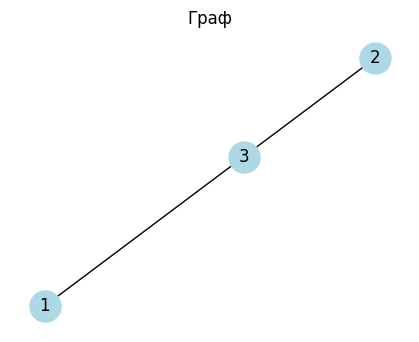

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3))
nx.draw(G, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Алгоритмы на графах**

Правда, в нашем задании вам нужно будет реализовать свои, но полезно знать и библиотечные, чтобы можно было сравнить результаты.

In [ ]:
print(f"Кратчайший путь с 1 до 3: {nx.shortest_path(G, source=1, target=3)}")
print(f"Длина пути: {nx.shortest_path_length(G, source=1, target=3)}")
print(f"Все пути: {list(nx.all_shortest_paths(G, source=1, target=3))}")
print(f"Компоненты связности: {list(nx.connected_components(G))}")
bfs = list(nx.bfs_tree(G, source=1))
dfs = list(nx.dfs_tree(G, source=1))
print(f"BFS: {bfs}")
print(f"DFS: {dfs}")

Кратчайший путь с 1 до 3: [1, 3]
Длина пути: 1
Все пути: [[1, 3]]
Компоненты связности: [{1, 2, 3}]
BFS: [1, 3, 2]
DFS: [1, 3, 2]


**Сохранение графа**

Рекомендуем ваши сгенерированные графы сохранить, чтобы потом не перегенерировать их заново.

In [ ]:
# Так можно сохранить граф в файл, в специальном формате или же списком ребер
nx.write_graphml(G, "graph.graphml")
nx.write_edgelist(G, "edges.txt")

# А так можно будет загрузить граф
G_loaded = nx.read_graphml("graph.graphml")

### Так можно генерировать графы

**Случайный граф Эрдёша-Реньи.**


**Модель Эрдёша-Реньи** -- это классическая модель случайного графа, названная в честь венгерских математиков **Пала Эрдёша** и **Альфреда Реньи**, которые предложили её в 1959 году.

Идея генерации тут такая. Представьте, что у вас есть n вершин, и вы случайным образом проводите между ними рёбра. Модель Эрдёша-Реньи описывает два способа, как это можно сделать.

**Модель генерации erdos_renyi_graph(n, p) -- с вероятностью p**
- `n` -- количество вершин
- `p` -- вероятность того, что между любой парой вершин существует ребро (0 ≤ p ≤ 1)

**Как работает**
- Берём все возможные пары вершин (всего C(n,2) = n·(n-1)/2 пар)
- Для каждой пары независимо подбрасываем монетку с вероятностью успеха p
- Если успех -- добавляем ребро, если нет -- не добавляем

**Количество рёбер** -- случайное, в среднем p·C(n,2)

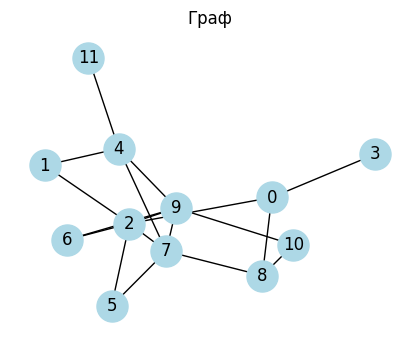

In [ ]:
G_er = nx.erdos_renyi_graph(12, 0.3)
plt.figure(figsize=(4, 3))
nx.draw(G_er, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Классический полный граф**

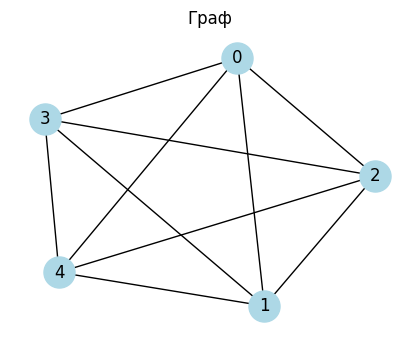

In [ ]:
G_complete = nx.complete_graph(5)
plt.figure(figsize=(4, 3))
nx.draw(G_complete, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Граф цикл**

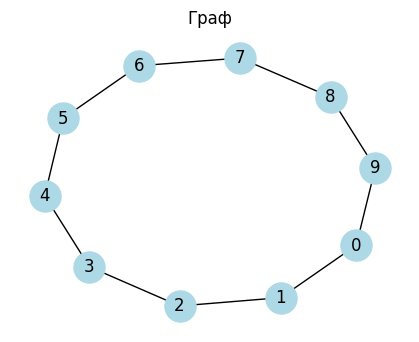

In [ ]:
G_cycle = nx.cycle_graph(10)
plt.figure(figsize=(4, 3))
nx.draw(G_cycle, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Сбалансированное дерево (balanced tree)** -- структура данных, в которой каждый узел имеет одинаковое количество потомков, а все листья находятся на примерно одинаковой глубине.

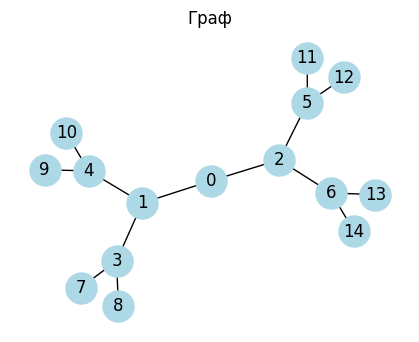

In [ ]:
G_tree = nx.balanced_tree(2, 3) # количество потомков, высота
plt.figure(figsize=(4, 3))
nx.draw(G_tree, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Как сделать взвешенный граф**

Используйте строго seed = 42

In [ ]:
import random

def add_random_weights(G, weight_range=(1, 10), seed=None):
    if seed is not None:
        random.seed(seed)

    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(weight_range[0], weight_range[1])

    return G

G_cycle = nx.cycle_graph(10)
G_cycle = add_random_weights(G_cycle, seed=42)

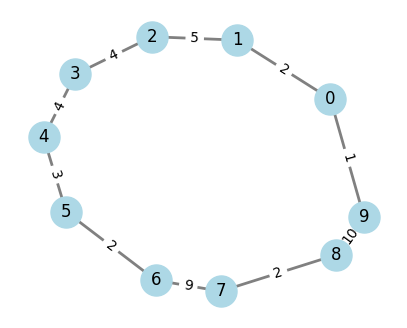

In [ ]:
plt.figure(figsize=(5, 4))
pos = nx.spring_layout(G_cycle, seed=42)
nx.draw_networkx_nodes(G_cycle, pos, node_color='lightblue',
                      node_size=500) # Рисуем вершины
nx.draw_networkx_labels(G_cycle, pos, font_size=12)
nx.draw_networkx_edges(G_cycle, pos, width=2, edge_color='gray') # Рисуем рёбра
edge_labels = nx.get_edge_attributes(G_cycle, 'weight') # Добавляем веса
nx.draw_networkx_edge_labels(G_cycle, pos, edge_labels=edge_labels,
                            font_size=10)
plt.axis('off')
plt.show()

# Задание 1 (1 балл)

Сгенерировать набор графов для последующего тестирования алгоритмов, используя библиотеку NetworkX.

**Размеры графов:**
- Количество вершин: от **10 до 1010**
- Шаг: **50** вершин
- Для каждого размера случайного графа сделать **5 графов**. Когда его будете тестировать, нужно делать тест на всех пяти графах одного размера и усреднять результат.

Обязательно, не забудьте, делать граф взвешенным (пригодится для задания 5).

Для случайново графа использовать seed = 42 (random).

**Каждого размера должно быть сгенерировано три типа графов (для разных случаев):**

| Тип | Описание | Случай |
|-----|----------|--------|
| **Полный граф** (complete graph) | Все вершины соединены со всеми | Скорее всего, это будет худший случай (максимум рёбер) |
| **Дерево** (tree) | Минимально связный граф (n-1 рёбер) | Скорее всего, это будет лучший случай (минимум рёбер) |
| **Случайный связный** | Эрдёша-Реньи c заданным seed random 42| Средний случай. Правда, может получиться не связным, вам это нужно учесть при запусках алгоритмов. |

**Сохранить графы таким образом (структура выходных данных)**

```
graphs_dataset/
├── complete/          # полные графы (худший случай)
│   ├── graph_n0010_1.txt
│   ├── graph_n0010_2.txt
│   └── ...
├── tree/              # деревья (лучший случай)
│   ├── graph_n0010_1.txt
│   └── ...
└── random/            # случайные связные (средний случай)
    ├── graph_n0010_1.txt
    └── ...
```

## Формат файла должен быть -- список рёбер

```
n m
5 5
1 3 5
2 7 4
...
```

где:
- первая строка: `n` (число вершин) и `m` (число рёбер)
- следующие `m` строк: ребра в формате `u v с` (нумерация с 0), откуда - куда - вес ребра

# Задание 2 (2 балла)

В этом задании мы исследуем различные способы представления графов в памяти компьютера и сравним их.

Рассмотрим три основных способа представления графов.

**1. Матрица смежности (Adjacency Matrix).**
Двумерный массив размером `|V| × |V|`, где `matrix[i][j] = 1`, если есть ребро из вершины `i` в вершину `j`, и `matrix[i][j] = 0` в противном случае.

**2. Список смежности (Adjacency List)**
Массив списков (или динамических массивов) размером `|V|`, где `list[i]` содержит всех соседей вершины `i`.

**3. Список рёбер (Edge List)**
Обычный список, каждый элемент которого — это кортеж `(u, v)` или `(u, v, weight)` для взвешенных графов.

Вам нужно экспериментально проверить теоретические оценки сложности операций над графами для трёх основных способов представления:
* Матрица смежности
* Список смежности
* Список рёбер

Реализуйте классы для трёх способов представления графа, вы можете добавлять дополнительные методы. Используйте глобальную переменную `operations_count` для подсчёта операций (как в примере с факториалом).

In [ ]:
operations_count = 0

class AdjacencyMatrix:
    def __init__(self, n):
        self.V = n
        self.matrix = [[0] * n for _ in range(n)]

    def add_edge(self, u, v):
        pass

    def remove_edge(self, u, v):
        pass

    def has_edge(self, u, v):
        pass

    def add_vertex(self):
        pass

    def remove_vertex(self, v):
        pass

    def is_isolated(self, v):
        pass

In [ ]:
operations_count = 0

class AdjacencyList:
    def __init__(self, n):
        self.V = n
        self.adj_list = [[] for _ in range(n)]

    def add_edge(self, u, v):
        pass

    def remove_edge(self, u, v):
        pass

    def has_edge(self, u, v):
        pass

    def add_vertex(self):
        pass

    def remove_vertex(self, v):
        pass

    def is_isolated(self, v):
        pass

In [ ]:
operations_count = 0

class EdgeList:
    def __init__(self, n):
        self.V = n
        self.edges = set()
        self.vertices = set(range(n))

    def add_edge(self, u, v):
        pass

    def remove_edge(self, u, v):
        pass

    def has_edge(self, u, v):
        pass

    def add_vertex(self):
        pass

    def remove_vertex(self, v):
        pass

    def is_isolated(self, v):
        pass

Для каждого типа представления и каждой операции измерьте для плотных графов (худший случай) размера от 10 до 1010 с шагом 50 измерьте количество операций. Используйте ранее сохраненные графы для экспериментов.

Постройте графики зависимости количества операций от размера графа по типам операции. На каждом графике должны быть три линии (матрица, список, список рёбер).

По результатам экспериментов заполните таблицу:

| Операция | Матрица смежности | Список смежности | Список рёбер |
|----------|-------------------|-------------------|--------------|
| **Память** |  |  |  |
| **Инициализация** |  |  |  |
| **Вставка вершины** |  |  |  |
| **Удаление вершины** |  |  |  |
| **Вставка ребра** |  |  |  |
| **Поиск/удаление ребра** |  |  |  |
| **Проверка изолированности вершины** |  |  |  |

**Ответьте на контрольные вопросы ниже:**
1. Совпадают ли экспериментальные результаты с теоретическими оценками?
2. Для каких операций разница наиболее заметна?
3. Почему вставка вершины в матрицу смежности требует O(V²)?
4. Почему список рёбер так плох для операции поиска ребра?
5. Какой способ представления лучше всего подходит для:
* Алгоритма Дейкстры?
* Алгоритма Флойда?
* BFS/DFS?
* Хранения разреженных графов?
* Хранения плотных графов?

# Задание 3 (2 балла)

В этом задании нужно исследовать и сравнить две реализации обхода графа в глубину:
* Рекурсивный DFS
* Нерекурсивный DFS

Реализуйте две функции обхода графа в глубину:

In [ ]:
def dfs_recursive(adj_list, start, visited=None):
    """
    Рекурсивный обход в глубину

    Аргументы:
        adj_list: список смежности графа
        start: начальная вершина
        visited: список посещённых вершин

    Возвращает:
        order: порядок обхода вершин
        operations: количество выполненных операций
        max_depth: максимальная глубина рекурсии
    """
    # TODO: реализовать
    pass

In [ ]:
def dfs_iterative(adj_list, start):
    """
    Нерекурсивный обход в глубину с использованием явного стека

    Аргументы:
        adj_list: список смежности графа
        start: начальная вершина

    Возвращает:
        order: порядок обхода вершин
        operations: количество выполненных операций
        max_stack_size: максимальный размер стека
    """
    # TODO: реализовать
    pass

Используйте графы из ранее сгенерированного набора:
- `graphs_dataset/tree/`
- `graphs_dataset/random/`
- `graphs_dataset/complete/`

Для каждого графа от 10 до 1010 вершин с шагом 50 и каждой реализации алгоритма измеряем:

| Метрика | Как измеряем |
|---------|--------------|
| **Количество операций** | Счётчик в коде (посещения вершин, проверки рёбер) |
| **Глубина рекурсии / размер стека** | Максимальная глубина при обходе |

Не забудьте! Граф может быть не связным, а обойти его нужно весь.

Постройте графики для двух реализаций DFS:
* Зависимости числа операций от размера графа
* Зависимости глубины рекурсии / размера стека от размера графа


**Ответьте на контрольные вопросы**

1. Какая асимптотическая сложность у DFS? Подтверждается ли она экспериментально?
2. Количество операций примерно одинаково для обеих реализаций? Почему?
3. Какая реализация быстрее? Почему? Какая реализация использует меньше памяти? При каких условиях рекурсивный DFS может упасть с ошибкой?
4. Как тип графа влияет на производительность?
4. Когда стоит использовать рекурсивный DFS?
6. Когда стоит использовать нерекурсивный DFS?
7. Какой способ лучше для очень глубоких графов?

# Задание 4 (2 балла)

Исследовать обхода графа в ширину BFS (нерекурсивный).

Реализуйте функцию обхода графа в ширину:

In [ ]:
from collections import deque

def bfs_iterative(graph, start):
    """
    Нерекурсивный обход в ширину с использованием очереди

    Аргументы:
        graph: список смежности графа
        start: начальная вершина

    Возвращает:
        order: порядок обхода вершин
        operations: количество выполненных операций
        distances: расстояния от start до всех вершин
    """
    pass

Используйте графы из ранее сгенерированного набора:
- `graphs_dataset/tree/`
- `graphs_dataset/random/`
- `graphs_dataset/complete/`

Для каждого графа от 10 до 1010 вершин с шагом 50 измеряем:

| Метрика | Как измеряем |
|---------|--------------|
| **Количество операций** | Счётчик в коде (посещения вершин, проверки рёбер) |

Не забудьте! Граф может быть не связным, а обойти его нужно весь.

Постройте график зависимости числа операций от размера графа.

**Ответьте на контрольные вопросы**

1. Какая асимптотическая сложность у BFS? Подтверждается ли она экспериментально?
2. Какой максимальный размер очереди для разных типов графов?
3. Почему для полного графа очередь быстро растёт?
4. Когда стоит использовать BFS? Когда стоит использовать DFS?

# Задание 5 (3 балла)

В этом задании поработаем с поиском кратчайших путей и исследуем три алгоритма:
* Алгоритм Дейкстры (Dijkstra)
* Алгоритм Беллмана-Форда (Bellman-Ford)
* Алгоритм Флойда-Уоршелла (Floyd-Warshall)

Реализуйте функции для трёх алгоритмов. Обратите внимание на возвращаемые значения и подсчет операций.

In [ ]:
import heapq
import math
from collections import deque

operations = 0

def dijkstra(adj_list, start):
    """
    Алгоритм Дейкстры для поиска кратчайших путей от start.

    Аргументы:
        adj_list: список смежности для ВЗВЕШЕННОГО графа.
                  Формат: adj_list[u] = [(v, weight), ...]
        start: начальная вершина.

    Возвращает:
        distances: список кратчайших расстояний от start до каждой вершины.
                   Если вершина недостижима, расстояние равно float('inf').
        operations: общее количество выполненных операций.
    """
    # TODO: Реализовать алгоритм Дейкстры.
    # Важно: Для подсчета операций считайте каждое:
    # - извлечение из кучи (pop)
    # - добавление в кучу (push)
    # - проверку и обновление расстояния (релаксацию)
    pass

In [ ]:
def bellman_ford(adj_list, start):
    """
    Алгоритм Беллмана-Форда для поиска кратчайших путей от start.

    Аргументы:
        adj_list: список смежности для ВЗВЕШЕННОГО графа.
                  Формат: adj_list[u] = [(v, weight), ...]
        start: начальная вершина.

    Возвращает:
        distances: список кратчайших расстояний от start до каждой вершины.
                   Если вершина недостижима, расстояние равно float('inf').
        has_negative_cycle: булево значение, указывающее, обнаружен ли отрицательный цикл.
        operations: общее количество выполненных операций.
    """
    # TODO: Реализовать алгоритм Беллмана-Форда.
    # Важно: После V-1 итерации релаксации выполните V-ю итерацию для поиска цикла.
    # Подсчитывайте операции на каждой итерации и каждой релаксации ребра.
    pass

In [ ]:
def floyd_warshall(weight_matrix):
    """
    Алгоритм Флойда-Уоршелла для поиска кратчайших путей между всеми парами вершин.

    Аргументы:
        weight_matrix: квадратная матрица весов размера VxV.
                       weight_matrix[u][v] содержит вес ребра (u, v),
                       или float('inf'), если ребра нет.

    Возвращает:
        dist: итоговая матрица кратчайших расстояний.
        operations: общее количество выполненных операций.
    """
    # TODO: Реализовать алгоритм Флойда-Уоршелла.
    # Важно: Считайте каждую проверку и обновление матрицы как одну операцию.
    pass

**Проведите эксперименты**

Используйте графы с количеством вершин от 10 до 1010 с шагом 50 (если для Флойда-Уоршела будет слишком долгий расчет, возьмете ограничение в 500).

Нужно провести эксперименты (то есть замерить число операций) для лучшего, среднего и худшего случая тремя алгоритмами.

**Графики**

Постройте графики для каждого из трех алгоритмов (Дейкстра, Беллман-Форд, Флойд-Уоршелл), показывающие зависимость количества операций от размера графа (V) для разных типов графов.

**Контрольные вопросы**

1. Совпадают ли результаты экспериментов с теоретической оценкой сложности алгоритмов? Почему?

2. На каких графах Дейкстра работает быстрее? Когда использование Беллмана-Форда является необходимостью (даже если он медленнее)?

3. Представьте, что нужно найти расстояния кратчайшие между всеми парами вершин. Для какого типа графов (плотных или разреженных) выгоднее запустить алгоритм Дейкстры из каждой вершины, а для каких — использовать Флойда-Уоршелла? Почему?